# Actividad — MLP para clasificación de prendas (Fashion-MNIST)
**Aprendizaje Supervisado · Sesión 11 · Redes neuronales para clasificación**

**Estudiante:** Julian Emiliano Ortiz Rivero

**Qué haremos.** En la presentación construimos un MLP capa por capa: perceptrón $\to$ arquitectura
multicapa (A), funciones de activación (B), backpropagation (C) y, finalmente, cómo entrenarlo en la
práctica con `MLPClassifier` --- eligiendo `solver`, `batch_size`, `learning_rate_init` y
`early_stopping` (D). Hoy aplicas todo eso a un problema real de **10 clases**: reconocer prendas de
ropa a partir de imágenes de $28\times 28$ píxeles (un subconjunto de **Fashion-MNIST**).

Trabaja **de forma individual**. Las celdas con `...` están incompletas: reemplaza los puntos
suspensivos con el código que falta (el comentario `✏️` te da una pista de qué se espera).

## Parte 0 — Los datos

Cada imagen es una matriz de $28\times 28$ píxeles en escala de grises (valores de 0 a 255), aplanada a
un vector de 784 variables. Hay 10 clases de prendas y, para que el entrenamiento sea rápido en esta
sesión, trabajamos con un **subconjunto balanceado**: 4 000 imágenes de entrenamiento y 1 000 de
prueba (400 y 100 por clase, respectivamente).

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110})

datos = np.load("datos-fashion-mnist-subset.npz")
X_train, y_train = datos["X_train"], datos["y_train"]
X_test, y_test = datos["X_test"], datos["y_test"]

nombres_clase = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                  "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("X_train:", X_train.shape, "  X_test:", X_test.shape)
pd.Series(y_train).value_counts().sort_index()

X_train: (4000, 28, 28)   X_test: (1000, 28, 28)


0    400
1    400
2    400
3    400
4    400
5    400
6    400
7    400
8    400
9    400
Name: count, dtype: int64

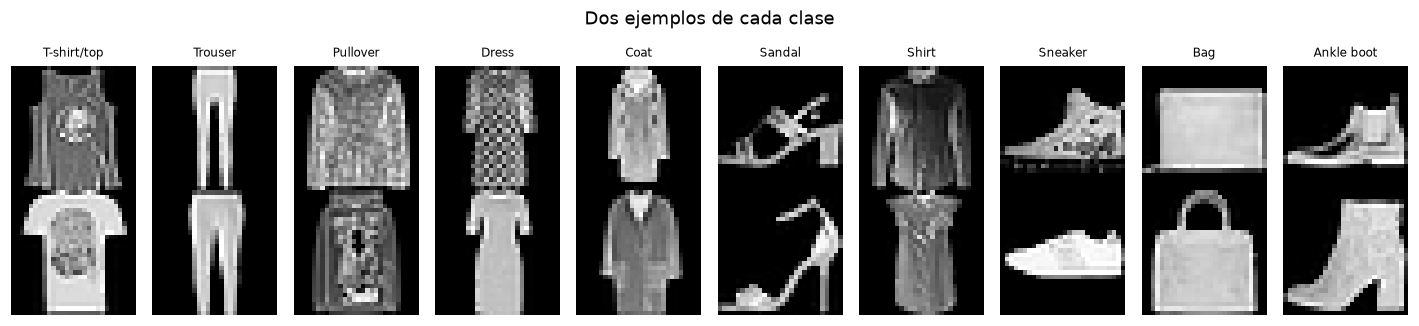

In [2]:
fig, axs = plt.subplots(2, 10, figsize=(13, 3))
for clase in range(10):
    idx_clase = np.where(y_train == clase)[0]
    for fila in range(2):
        ax = axs[fila, clase]
        ax.imshow(X_train[idx_clase[fila]], cmap="gray")
        ax.axis("off")
        if fila == 0:
            ax.set_title(nombres_clase[clase], fontsize=8)
plt.suptitle("Dos ejemplos de cada clase"); plt.tight_layout(); plt.show()

✏️ **Pregunta 0.1.** (a) ¿Está balanceado el conjunto de entrenamiento entre las 10 clases? (b)
Mirando los ejemplos de la celda anterior, ¿qué grupo de 2 o 3 prendas te parece, a simple vista, más
fácil de confundir entre sí?

**Respuesta:** El conjunto está balanceado porque contiene 400 imágenes de cada clase. A simple vista, camiseta, pulóver y camisa forman el grupo más parecido por su silueta.

## Parte 1 — Preparar los datos: escalado  *(presentación D7)*

Las imágenes vienen con píxeles en el rango $[0, 255]$. Como vimos en D7, una MLP combina las variables
con sumas ponderadas, así que una escala tan grande ralentiza y desestabiliza el entrenamiento.
Aplanamos cada imagen a un vector y escalamos a $[0, 1]$.

In [3]:
X_train_flat = X_train.reshape(len(X_train), -1)   # (4000, 28, 28) -> (4000, 784)
X_test_flat = X_test.reshape(len(X_test), -1)

X_train_s = X_train_flat / 255.0
X_test_s = X_test_flat / 255.0

print("Antes de escalar -- min:", X_train_flat.min(), " max:", X_train_flat.max())
print("Después de escalar -- min:", X_train_s.min(), " max:", X_train_s.max())

Antes de escalar -- min: 0  max: 255
Después de escalar -- min: 0.0  max: 1.0


✏️ **Pregunta 1.1.** En la presentación (D7) se comparó esto con los árboles de decisión. ¿Por qué
un árbol **no** necesita este paso de escalado, pero una MLP sí?

**Respuesta:** Un árbol compara una variable con un umbral. Cambiar sus unidades también cambia el umbral, pero no el orden de los casos ni el corte. Una MLP combina todas las variables mediante sumas ponderadas y descenso de gradiente. Si unas entradas son mucho mayores que otras, producen pasos desiguales y vuelven el entrenamiento más lento o inestable.

## Parte 2 — Una primera MLP  *(presentación D1–D2)*

Entrenamos una MLP con la misma arquitectura usada en la presentación (D8): dos capas ocultas de 128 y
64 neuronas, activación ReLU, optimizador `adam` (el valor por defecto).

In [4]:
mlp_base = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu",
                         solver="adam", max_iter=60, random_state=0).fit(X_train_s, y_train)

print("Exactitud en entrenamiento:", round(mlp_base.score(X_train_s, y_train), 4))
print("Exactitud en prueba:", round(mlp_base.score(X_test_s, y_test), 4))

Exactitud en entrenamiento: 0.9683
Exactitud en prueba: 0.817


✏️ **Pregunta 2.1.** ¿Qué exactitud obtuvo esta primera MLP en prueba? ¿La exactitud de
entrenamiento es claramente mayor que la de prueba? ¿Qué sugiere eso?

**Respuesta:** La exactitud de prueba fue 0.8170, mientras entrenamiento alcanzó 0.9683. La diferencia de 0.1513 es clara y sugiere que el modelo se ajustó demasiado a las imágenes de entrenamiento.

## Parte 3 — El optimizador: `solver`  *(presentación D3)*

Comparamos los tres optimizadores de `MLPClassifier` con la misma arquitectura y el mismo presupuesto
de iteraciones, midiendo exactitud en prueba y tiempo de entrenamiento.

In [5]:
resultados_solver = []
for solver in ["lbfgs", "sgd", "adam"]:     # ✏️ los tres solvers vistos en D3
    inicio = time.time()
    modelo = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu",
                            solver=solver, max_iter=60, random_state=0).fit(X_train_s, y_train)
    segundos = time.time() - inicio
    resultados_solver.append({
        "solver": solver,
        "exactitud_prueba": round(modelo.score(X_test_s, y_test), 4),
        "segundos": round(segundos, 1),
    })

tabla_solver = pd.DataFrame(resultados_solver)
tabla_solver

,solver,exactitud_prueba,segundos
0,lbfgs,0.780,3.9
1,sgd,0.772,4.6
2,adam,0.817,5.4


✏️ **Pregunta 3.1.** ¿Qué solver obtuvo la mejor exactitud? ¿Cuál fue el más rápido? ¿Es consistente
con lo que dice la tabla de D3 sobre cuándo conviene cada uno?

**Respuesta:** `adam` obtuvo la mejor exactitud, 0.8170. En esta ejecución, `lbfgs` fue el más rápido con 3.9 segundos, seguido por `sgd` con 4.6. El resultado es razonable: `lbfgs` puede ser competitivo en conjuntos pequeños, mientras `adam` suele funcionar mejor como punto de partida en conjuntos medianos. El tiempo puede cambiar según el equipo.

## Parte 4 — `batch_size` y `learning_rate_init`  *(presentación D4–D5)*

Con `solver="sgd"` (donde estos dos hiperparámetros son más visibles), comparamos un lote pequeño
contra uno grande, y una tasa de aprendizaje razonable contra una demasiado grande --- graficando la
curva de pérdida (`loss_curve_`) de cada combinación.

batch=16, lr=0.01 (equilibrado)      exactitud de prueba: 0.8020


batch=2000, lr=0.01 (lote grande)    exactitud de prueba: 0.7680


batch=16, lr=1.5 (muy grande)        exactitud de prueba: 0.1000


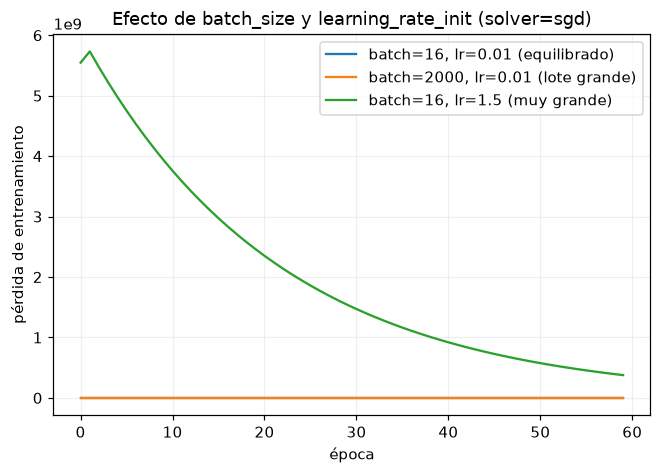

In [6]:
configs = [
    {"batch_size": 16,   "learning_rate_init": 0.01,  "label": "batch=16, lr=0.01 (equilibrado)"},
    {"batch_size": 2000, "learning_rate_init": 0.01,  "label": "batch=2000, lr=0.01 (lote grande)"},
    {"batch_size": 16,   "learning_rate_init": 1.5,   "label": "batch=16, lr=1.5 (muy grande)"},
]

plt.figure(figsize=(7, 4.5))
for cfg in configs:
    modelo = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", solver="sgd",
                            batch_size=cfg["batch_size"], learning_rate_init=cfg["learning_rate_init"],
                            max_iter=60, random_state=0).fit(X_train_s, y_train)
    plt.plot(modelo.loss_curve_, label=cfg["label"])
    print(f"{cfg['label']:35s}  exactitud de prueba: {modelo.score(X_test_s, y_test):.4f}")

plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento")
plt.title("Efecto de batch_size y learning_rate_init (solver=sgd)")
plt.legend(); plt.grid(alpha=0.2); plt.show()

✏️ **Pregunta 4.1.** (a) ¿Qué configuración muestra la curva más ruidosa? (b) ¿Qué configuración
diverge u oscila, y coincide con lo que D5 predice para un `learning_rate_init` muy grande? (c) ¿Cuál
de las tres te parece el mejor punto de partida?

**Respuesta:** El lote de 16 con tasa 0.01 muestra más ruido que el lote de 2,000 porque estima el gradiente con menos ejemplos. La tasa 1.5 oscila y termina con exactitud 0.10, tal como se esperaba para un paso demasiado grande. El mejor punto de partida es lote 16 con tasa 0.01, que alcanzó 0.8020 y mantuvo una pérdida descendente.

## Parte 5 — Early stopping y evaluación final  *(presentación D6, D9)*

Entrenamos el modelo final con `early_stopping=True` (reservando una fracción de entrenamiento como
validación interna) y revisamos `loss_curve_` junto con `validation_scores_`, tal como describe D9.

Número de épocas hasta detenerse: 23  de un máximo de 200
Exactitud en prueba: 0.803


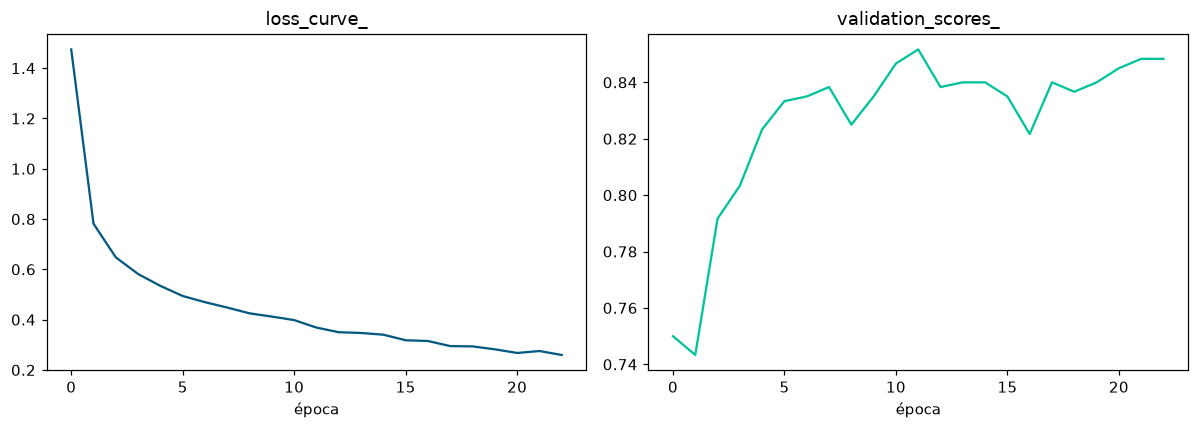

In [7]:
mlp_final = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
                          alpha=1e-4, early_stopping=True, validation_fraction=0.15,
                          n_iter_no_change=10, max_iter=200, random_state=0).fit(X_train_s, y_train)

print("Número de épocas hasta detenerse:", mlp_final.n_iter_, " de un máximo de", mlp_final.max_iter)
print("Exactitud en prueba:", round(mlp_final.score(X_test_s, y_test), 4))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(mlp_final.loss_curve_, color="#065A82"); axs[0].set_title("loss_curve_"); axs[0].set_xlabel("época")
axs[1].plot(mlp_final.validation_scores_, color="#02C39A"); axs[1].set_title("validation_scores_"); axs[1].set_xlabel("época")
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

 T-shirt/top       0.75      0.79      0.77       100
     Trouser       0.94      0.97      0.96       100
    Pullover       0.83      0.48      0.61       100
       Dress       0.76      0.81      0.78       100
        Coat       0.69      0.79      0.73       100
      Sandal       0.92      0.87      0.89       100
       Shirt       0.54      0.58      0.56       100
     Sneaker       0.84      0.95      0.89       100
         Bag       0.92      0.93      0.93       100
  Ankle boot       0.91      0.86      0.89       100

    accuracy                           0.80      1000
   macro avg       0.81      0.80      0.80      1000
weighted avg       0.81      0.80      0.80      1000



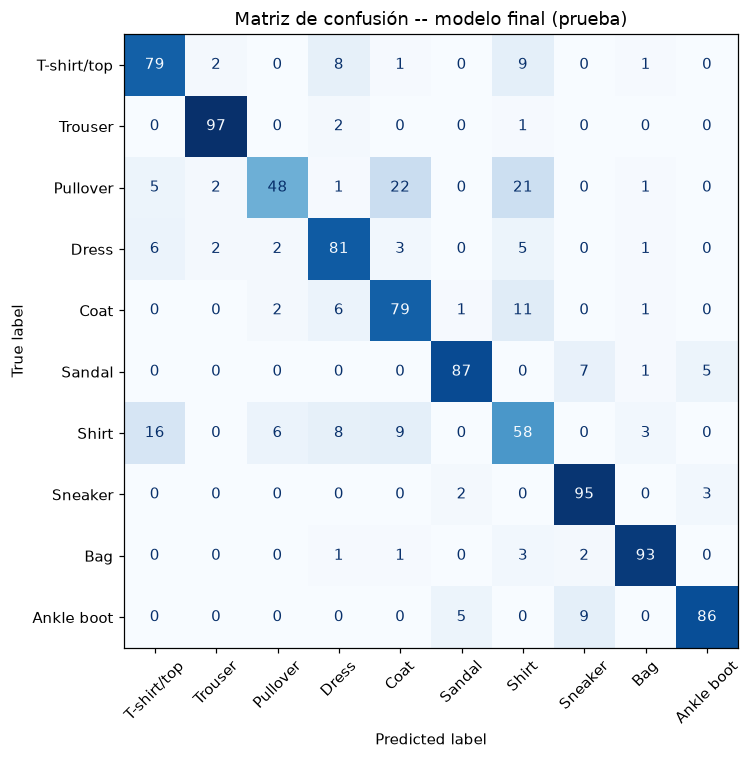

In [8]:
pred = mlp_final.predict(X_test_s)
print(classification_report(y_test, pred, target_names=nombres_clase))

fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=nombres_clase,
                                         cmap="Blues", colorbar=False, xticks_rotation=45, ax=ax)
ax.set_title("Matriz de confusión -- modelo final (prueba)")
plt.tight_layout(); plt.show()

In [9]:
cm = confusion_matrix(y_test, pred)
cm_sin_diag = cm.copy()
np.fill_diagonal(cm_sin_diag, 0)
i, j = np.unravel_index(np.argmax(cm_sin_diag), cm_sin_diag.shape)
print(f"Confusión más frecuente: {nombres_clase[i]} clasificada como {nombres_clase[j]}  ({cm_sin_diag[i, j]} casos)")

pares = np.argwhere(cm_sin_diag >= 5)
print("\\nPares con 5 o más confusiones:")
for fi, fj in pares:
    print(f"  {nombres_clase[fi]:12s} -> {nombres_clase[fj]:12s} : {cm_sin_diag[fi, fj]}")

Confusión más frecuente: Pullover clasificada como Coat  (22 casos)
\nPares con 5 o más confusiones:
  T-shirt/top  -> Dress        : 8
  T-shirt/top  -> Shirt        : 9
  Pullover     -> T-shirt/top  : 5
  Pullover     -> Coat         : 22
  Pullover     -> Shirt        : 21
  Dress        -> T-shirt/top  : 6
  Dress        -> Shirt        : 5
  Coat         -> Dress        : 6
  Coat         -> Shirt        : 11
  Sandal       -> Sneaker      : 7
  Sandal       -> Ankle boot   : 5
  Shirt        -> T-shirt/top  : 16
  Shirt        -> Pullover     : 6
  Shirt        -> Dress        : 8
  Shirt        -> Coat         : 9
  Ankle boot   -> Sandal       : 5
  Ankle boot   -> Sneaker      : 9


✏️ **Pregunta 5.1.** (a) ¿El modelo se detuvo antes de llegar a `max_iter=200`? ¿Qué indica eso
sobre `early_stopping`? (b) ¿Cuál es la confusión más frecuente? (c) ¿Coincide con lo que anticipaste
en la Pregunta 0.1?

**Respuesta:** El entrenamiento se detuvo en la época 23, mucho antes del máximo de 200. Esto indica que la validación dejó de mejorar durante el margen configurado y la detención temprana evitó seguir ajustando. La confusión más frecuente fue pulóver clasificado como abrigo, con 22 casos. Coincide con la expectativa inicial de que camiseta, pulóver y camisa serían difíciles de separar, aunque el abrigo también resultó muy parecido.

---
**Para explorar (opcional).** Prueba a aumentar `hidden_layer_sizes` (p. ej. `(256, 128)`) o a quitar
el escalado de la Parte 1 por completo --- ¿qué le pasa al entrenamiento sin él?